In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

DATA_PATH = Path("../data/raw/career_dataset_large.xlsx")
df = pd.read_excel(DATA_PATH)

print("Career dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Career dataset loaded successfully!
Shape: (5000, 6)
Columns: ['Education Level', 'Specialization', 'Skills', 'Certifications', 'CGPA/Percentage', 'Recommended Career']


In [3]:
df.head()

,Education Level,Specialization,Skills,Certifications,CGPA/Percentage,Recommended Career
0,Bachelor's,Finance,"Counseling, MS Office, Machine Learning",Tally ERP,67,Business Analyst
1,Intermediate,Science,"Accounting, MS Office",AWS Certified,67,Software Engineer
2,Master's,Business,"Accounting, SQL, Data Analysis",Mental Health Basics,90,Financial Analyst
3,Bachelor's,Computer Science,Communication,NaN,75,Clerk
4,Matric,Business,Data Analysis,Tally ERP,83,Sales Assistant


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Education Level         0
Specialization          0
Skills                  0
Certifications        596
CGPA/Percentage         0
Recommended Career      0
dtype: int64

Duplicate Rows:


1


In [5]:
career_df = df.copy()

# Remove duplicate rows
career_df = career_df.drop_duplicates().reset_index(drop=True)

# Fill missing certifications
career_df["Certifications"] = (
    career_df["Certifications"].fillna("No Certification")
)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", career_df.shape)

print("\nMissing values after cleaning:")
print(career_df.isnull().sum())

print("\nDuplicate rows after cleaning:", career_df.duplicated().sum())

Original dataset shape: (5000, 6)
Cleaned dataset shape: (4999, 6)

Missing values after cleaning:
Education Level       0
Specialization        0
Skills                0
Certifications        0
CGPA/Percentage       0
Recommended Career    0
dtype: int64

Duplicate rows after cleaning: 0


In [6]:
# Separate input features and target
X = career_df.drop(columns=["Recommended Career"])
y = career_df["Recommended Career"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput feature columns:")
print(X.columns.tolist())

print("\nTarget career categories:")
print(y.nunique())
print(sorted(y.unique()))

Input features shape: (4999, 5)
Target shape: (4999,)

Input feature columns:
['Education Level', 'Specialization', 'Skills', 'Certifications', 'CGPA/Percentage']

Target career categories:
12
['Business Analyst', 'Clerk', 'Data Entry Operator', 'Financial Analyst', 'Junior Accountant', 'ML Engineer', 'Marketing Executive', 'Professor', 'Research Scientist', 'Sales Assistant', 'School Counselor', 'Software Engineer']


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# Preprocess numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            ["CGPA/Percentage"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            [
                "Education Level",
                "Specialization",
                "Certifications"
            ]
        ),
        (
            "skills",
            TfidfVectorizer(),
            "Skills"
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining career distribution:")
print(y_train.value_counts().sort_index())

Training features: (3999, 5)
Testing features: (1000, 5)

Training target: (3999,)
Testing target: (1000,)

Training career distribution:
Recommended Career
Business Analyst       316
Clerk                  346
Data Entry Operator    330
Financial Analyst      330
Junior Accountant      330
ML Engineer            342
Marketing Executive    346
Professor              326
Research Scientist     335
Sales Assistant        330
School Counselor       334
Software Engineer      334
Name: count, dtype: int64


In [9]:
# Fit preprocessing on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nTraining data type:", type(X_train_processed))
print("Testing data type:", type(X_test_processed))

Processed training shape: (3999, 35)
Processed testing shape: (1000, 35)

Training data type: <class 'scipy.sparse._csr.csr_matrix'>
Testing data type: <class 'scipy.sparse._csr.csr_matrix'>


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create the model
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_processed, y_train)

# Predict careers for test data
y_pred_lr = lr_model.predict(X_test_processed)

# Evaluate the model
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Logistic Regression Accuracy: 7.1 %

Classification Report:
                     precision    recall  f1-score   support

   Business Analyst       0.06      0.04      0.05        79
              Clerk       0.08      0.13      0.10        86
Data Entry Operator       0.07      0.05      0.06        83
  Financial Analyst       0.04      0.06      0.05        83
  Junior Accountant       0.08      0.07      0.08        83
        ML Engineer       0.05      0.06      0.05        86
Marketing Executive       0.11      0.14      0.12        86
          Professor       0.04      0.02      0.03        81
 Research Scientist       0.09      0.12      0.10        84
    Sales Assistant       0.06      0.06      0.06        83
   School Counselor       0.07      0.07      0.07        83
  Software Engineer       0.06      0.02      0.03        83

           accuracy                           0.07      1000
          macro avg       0.07      0.07      0.07      1000
       weighted avg    

In [11]:
# Compare actual and predicted careers
comparison = pd.DataFrame({
    "Actual Career": y_test.reset_index(drop=True),
    "Predicted Career": y_pred_lr
})

print("First 20 predictions:")
display(comparison.head(20))

print("\nActual career distribution:")
print(y_test.value_counts())

print("\nPredicted career distribution:")
print(pd.Series(y_pred_lr).value_counts())

print("\nNumber of correct predictions:",
      (y_test.to_numpy() == y_pred_lr).sum())

First 20 predictions:


,Actual Career,Predicted Career
0,Clerk,Clerk
1,Business Analyst,Sales Assistant
2,Marketing Executive,Professor
3,Professor,Financial Analyst
4,Sales Assistant,Software Engineer
5,Sales Assistant,School Counselor
6,Data Entry Operator,Research Scientist
7,Junior Accountant,Financial Analyst
8,Data Entry Operator,Research Scientist
9,Professor,Software Engineer



Actual career distribution:
Recommended Career
Clerk                  86
Marketing Executive    86
ML Engineer            86
Research Scientist     84
School Counselor       83
Junior Accountant      83
Sales Assistant        83
Data Entry Operator    83
Software Engineer      83
Financial Analyst      83
Professor              81
Business Analyst       79
Name: count, dtype: int64

Predicted career distribution:
Clerk                  139
Financial Analyst      115
Marketing Executive    108
Research Scientist     108
ML Engineer            105
School Counselor        88
Sales Assistant         80
Junior Accountant       72
Data Entry Operator     60
Business Analyst        47
Professor               46
Software Engineer       32
Name: count, dtype: int64

Number of correct predictions: 71


In [12]:
# Inspect the relationship between skills and recommended careers
skills_check = career_df[["Skills", "Recommended Career"]].copy()

skills_check["Skills"] = (
    skills_check["Skills"]
    .fillna("")
    .str.strip()
)

print("Unique skill combinations:",
      skills_check["Skills"].nunique())

print("\nMost common skill combinations:")
print(skills_check["Skills"].value_counts().head(15))

print("\nMost common skills associated with each career:")
for career in sorted(skills_check["Recommended Career"].unique()):
    print(f"\n{career}:")
    print(
        skills_check.loc[
            skills_check["Recommended Career"] == career, "Skills"
        ].value_counts().head(3)
    )

Unique skill combinations: 757

Most common skill combinations:
Skills
Accounting                      204
Python                          179
Financial Analysis              174
SQL                             172
Data Analysis                   171
Marketing                       168
MS Office                       167
Counseling                      162
Communication                   160
Machine Learning                155
SQL, Data Analysis               30
Data Analysis, MS Office         29
Financial Analysis, SQL          26
Counseling, Python               26
Machine Learning, Accounting     25
Name: count, dtype: int64

Most common skills associated with each career:

Business Analyst:
Skills
Accounting    17
Python        17
Marketing     16
Name: count, dtype: int64

Clerk:
Skills
Accounting       29
Communication    20
Data Analysis    20
Name: count, dtype: int64

Data Entry Operator:
Skills
Accounting    21
MS Office     18
SQL           16
Name: count, dtype: int64

Fin

In [13]:
# Check whether identical skill combinations map to different careers
skill_career_counts = (
    career_df.groupby("Skills")["Recommended Career"]
    .nunique()
    .sort_values(ascending=False)
)

print("Skill combinations linked to multiple careers:")
print(skill_career_counts.head(15))

print(
    "\nSkill combinations linked to more than one career:",
    (skill_career_counts > 1).sum()
)

print(
    "Skill combinations linked to only one career:",
    (skill_career_counts == 1).sum()
)

# Inspect the most frequent skill combination for each career
print("\nMost frequent skill combination per career:")

for career, group in career_df.groupby("Recommended Career"):
    print(f"\n{career}")
    print(group["Skills"].value_counts().head(3))

Skill combinations linked to multiple careers:
Skills
SQL, MS Office              12
SQL                         12
Data Analysis               12
Python, Counseling          12
Python                      12
Marketing                   12
Communication               12
Machine Learning            12
Financial Analysis          12
MS Office                   12
Accounting                  12
Counseling                  12
MS Office, Accounting       11
MS Office, Python           11
Marketing, Communication    11
Name: Recommended Career, dtype: int64

Skill combinations linked to more than one career: 569
Skill combinations linked to only one career: 188

Most frequent skill combination per career:

Business Analyst
Skills
Accounting    17
Python        17
Marketing     16
Name: count, dtype: int64

Clerk
Skills
Accounting       29
Communication    20
Data Analysis    20
Name: count, dtype: int64

Data Entry Operator
Skills
Accounting    21
MS Office     18
SQL           16
Name: coun

In [14]:
# Check the number of careers associated with each feature value

features_to_check = [
    "Education Level",
    "Specialization",
    "Certifications"
]

for feature in features_to_check:
    print(f"\n{'=' * 50}")
    print(f"Feature: {feature}")

    career_counts = (
        career_df.groupby(feature, dropna=False)["Recommended Career"]
        .nunique()
        .sort_values(ascending=False)
    )

    print(career_counts)

print("\nCGPA/Percentage summary by career:")
display(
    career_df.groupby("Recommended Career")["CGPA/Percentage"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)


Feature: Education Level
Education Level
Bachelor's      12
Intermediate    12
Master's        12
Matric          12
PhD             12
Name: Recommended Career, dtype: int64

Feature: Specialization
Specialization
Arts                12
Business            12
Commerce            12
Computer Science    12
Engineering         12
Finance             12
Psychology          12
Science             12
Name: Recommended Career, dtype: int64

Feature: Certifications
Certifications
AWS Certified            12
CFA Level 1              12
Creative Writing         12
Digital Marketing        12
Google Data Analytics    12
Mental Health Basics     12
No Certification         12
Tally ERP                12
Name: Recommended Career, dtype: int64

CGPA/Percentage summary by career:


,count,mean,std,min,max
Recommended Career,,,,,
Business Analyst,395,77.78,10.16,60,95
Clerk,432,77.20,10.20,60,95
Data Entry Operator,413,77.24,10.33,60,95
Financial Analyst,413,77.23,10.56,60,95
Junior Accountant,413,77.21,10.37,60,95
ML Engineer,428,77.49,10.16,60,95
Marketing Executive,432,78.56,10.19,60,95
Professor,407,77.81,10.69,60,95
Research Scientist,419,77.45,10.28,60,95


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Predict careers
y_pred_rf = rf_model.predict(X_test_processed)

# Evaluate the model
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

Random Forest Accuracy: 8.1 %

Classification Report:
                     precision    recall  f1-score   support

   Business Analyst       0.09      0.08      0.08        79
              Clerk       0.08      0.08      0.08        86
Data Entry Operator       0.09      0.08      0.09        83
  Financial Analyst       0.07      0.07      0.07        83
  Junior Accountant       0.07      0.07      0.07        83
        ML Engineer       0.09      0.10      0.10        86
Marketing Executive       0.06      0.06      0.06        86
          Professor       0.08      0.07      0.08        81
 Research Scientist       0.07      0.06      0.06        84
    Sales Assistant       0.07      0.06      0.06        83
   School Counselor       0.11      0.11      0.11        83
  Software Engineer       0.11      0.12      0.11        83

           accuracy                           0.08      1000
          macro avg       0.08      0.08      0.08      1000
       weighted avg       0.0

In [18]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [20]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# Encode career labels for XGBoost
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train_processed, y_train_encoded)

# Predict
y_pred_xgb_encoded = xgb_model.predict(X_test_processed)
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded.astype(int)
)

# Evaluate
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", round(xgb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    zero_division=0
))

XGBoost Accuracy: 8.9 %

Classification Report:
                     precision    recall  f1-score   support

   Business Analyst       0.11      0.10      0.10        79
              Clerk       0.11      0.13      0.12        86
Data Entry Operator       0.15      0.13      0.14        83
  Financial Analyst       0.10      0.12      0.11        83
  Junior Accountant       0.10      0.10      0.10        83
        ML Engineer       0.04      0.05      0.05        86
Marketing Executive       0.11      0.10      0.11        86
          Professor       0.06      0.05      0.05        81
 Research Scientist       0.05      0.05      0.05        84
    Sales Assistant       0.06      0.05      0.05        83
   School Counselor       0.09      0.07      0.08        83
  Software Engineer       0.10      0.12      0.11        83

           accuracy                           0.09      1000
          macro avg       0.09      0.09      0.09      1000
       weighted avg       0.09     

In [21]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy (%)": [
        round(lr_accuracy * 100, 2),
        round(rf_accuracy * 100, 2),
        round(xgb_accuracy * 100, 2)
    ]
})

model_results = model_results.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(model_results)

,Model,Accuracy (%)
0,XGBoost,8.9
1,Random Forest,8.1
2,Logistic Regression,7.1


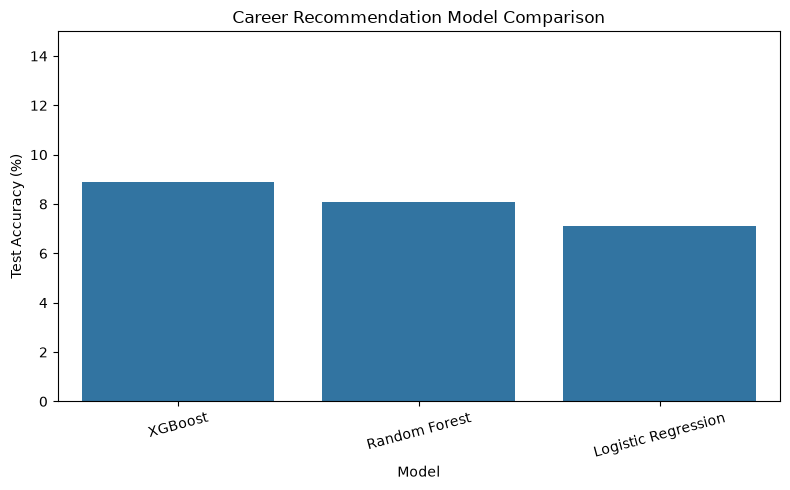

In [22]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Career Recommendation Model Comparison")
plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.ylim(0, 15)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [23]:
# Check repeated profiles and their career labels
input_columns = [
    "Education Level",
    "Specialization",
    "Skills",
    "Certifications",
    "CGPA/Percentage"
]

profile_counts = (
    career_df.groupby(input_columns, dropna=False)["Recommended Career"]
    .nunique()
)

print("Unique input profiles:", len(profile_counts))
print("Profiles linked to multiple careers:", (profile_counts > 1).sum())
print("Profiles linked to one career:", (profile_counts == 1).sum())

print("\nExamples of profiles linked to multiple careers:")

ambiguous_profiles = profile_counts[profile_counts > 1].head(5)

for profile in ambiguous_profiles.index:
    print("\nProfile:", profile)
    mask = (career_df[input_columns] == pd.Series(
        profile, index=input_columns
    )).all(axis=1)
    print(career_df.loc[mask, "Recommended Career"].value_counts())

Unique input profiles: 4984
Profiles linked to multiple careers: 15
Profiles linked to one career: 4969

Examples of profiles linked to multiple careers:

Profile: ("Bachelor's", 'Arts', 'Data Analysis, MS Office', 'Creative Writing', 86)
Recommended Career
Junior Accountant      1
Data Entry Operator    1
Name: count, dtype: int64

Profile: ("Bachelor's", 'Psychology', 'Accounting', 'Google Data Analytics', 65)
Recommended Career
Marketing Executive    1
Clerk                  1
Name: count, dtype: int64

Profile: ("Bachelor's", 'Psychology', 'Communication, Python', 'No Certification', 91)
Recommended Career
Financial Analyst    1
Software Engineer    1
Name: count, dtype: int64

Profile: ("Bachelor's", 'Psychology', 'MS Office', 'No Certification', 75)
Recommended Career
ML Engineer            1
Data Entry Operator    1
Name: count, dtype: int64

Profile: ('Intermediate', 'Business', 'Python', 'Google Data Analytics', 83)
Recommended Career
Data Entry Operator    1
Marketing Executi

In [24]:
# Get feature names from the fitted preprocessing pipeline
feature_names = preprocessor.get_feature_names_out()

# Get feature importance from XGBoost
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 most important features:")
display(importance_df.head(15))

# Summarize importance by feature group
importance_df["Feature Group"] = importance_df["Feature"].str.split("_").str[0]

print("\nTotal importance by feature group:")
display(
    importance_df.groupby("Feature Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .to_frame()
)

Top 15 most important features:


,Feature,Importance
0,cat__Certifications_Google Data Analytics,0.034828
1,cat__Education Level_Matric,0.033838
2,skills__analysis,0.033709
3,cat__Education Level_PhD,0.033262
4,skills__communication,0.032391
5,cat__Education Level_Intermediate,0.032259
6,skills__learning,0.032079
7,skills__python,0.031984
8,cat__Specialization_Arts,0.031878
9,cat__Certifications_Tally ERP,0.031474



Total importance by feature group:


,Importance
Feature Group,
cat,0.636921
skills,0.335053
num,0.028027


In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Baseline model: always predicts the most common training career
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

y_pred_dummy = dummy_model.predict(X_test)
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)

print("Dummy baseline accuracy:",
      round(dummy_accuracy * 100, 2), "%")

print("Logistic Regression accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("Random Forest accuracy:",
      round(rf_accuracy * 100, 2), "%")

print("XGBoost accuracy:",
      round(xgb_accuracy * 100, 2), "%")

Dummy baseline accuracy: 8.6 %
Logistic Regression accuracy: 7.1 %
Random Forest accuracy: 8.1 %
XGBoost accuracy: 8.9 %


In [26]:
# Career distribution across each feature
for feature in [
    "Education Level",
    "Specialization",
    "Certifications"
]:
    print(f"\n{'=' * 45}")
    print(f"Career distribution by {feature}")

    display(pd.crosstab(
        career_df[feature],
        career_df["Recommended Career"],
        normalize="index"
    ).round(2))


Career distribution by Education Level


Recommended Career,Business Analyst,Clerk,Data Entry Operator,Financial Analyst,Junior Accountant,ML Engineer,Marketing Executive,Professor,Research Scientist,Sales Assistant,School Counselor,Software Engineer
Education Level,,,,,,,,,,,,
Bachelor's,0.08,0.10,0.08,0.08,0.08,0.09,0.09,0.09,0.07,0.08,0.08,0.09
Intermediate,0.09,0.09,0.08,0.09,0.08,0.09,0.09,0.09,0.07,0.07,0.09,0.08
Master's,0.08,0.08,0.08,0.08,0.07,0.10,0.08,0.07,0.11,0.07,0.09,0.09
Matric,0.08,0.07,0.09,0.08,0.09,0.07,0.08,0.08,0.09,0.10,0.08,0.09
PhD,0.07,0.09,0.08,0.09,0.09,0.09,0.09,0.08,0.08,0.09,0.08,0.08



Career distribution by Specialization


Recommended Career,Business Analyst,Clerk,Data Entry Operator,Financial Analyst,Junior Accountant,ML Engineer,Marketing Executive,Professor,Research Scientist,Sales Assistant,School Counselor,Software Engineer
Specialization,,,,,,,,,,,,
Arts,0.08,0.09,0.06,0.09,0.09,0.08,0.10,0.10,0.09,0.08,0.08,0.08
Business,0.09,0.06,0.09,0.08,0.09,0.10,0.08,0.08,0.06,0.08,0.10,0.08
Commerce,0.08,0.07,0.11,0.07,0.10,0.09,0.08,0.07,0.07,0.09,0.08,0.07
Computer Science,0.10,0.10,0.09,0.08,0.06,0.09,0.07,0.07,0.10,0.08,0.08,0.08
Engineering,0.05,0.10,0.08,0.08,0.07,0.08,0.10,0.07,0.09,0.09,0.08,0.10
Finance,0.09,0.09,0.08,0.08,0.07,0.08,0.10,0.08,0.08,0.08,0.10,0.08
Psychology,0.07,0.10,0.08,0.10,0.10,0.09,0.07,0.08,0.09,0.08,0.07,0.08
Science,0.08,0.08,0.07,0.07,0.08,0.10,0.08,0.10,0.09,0.08,0.08,0.09



Career distribution by Certifications


Recommended Career,Business Analyst,Clerk,Data Entry Operator,Financial Analyst,Junior Accountant,ML Engineer,Marketing Executive,Professor,Research Scientist,Sales Assistant,School Counselor,Software Engineer
Certifications,,,,,,,,,,,,
AWS Certified,0.07,0.10,0.06,0.10,0.07,0.07,0.08,0.09,0.10,0.09,0.08,0.09
CFA Level 1,0.09,0.09,0.08,0.07,0.10,0.10,0.08,0.08,0.09,0.06,0.07,0.09
Creative Writing,0.09,0.08,0.08,0.07,0.09,0.08,0.10,0.09,0.07,0.10,0.07,0.09
Digital Marketing,0.07,0.08,0.07,0.09,0.08,0.09,0.09,0.09,0.08,0.08,0.08,0.10
Google Data Analytics,0.08,0.08,0.10,0.08,0.10,0.08,0.07,0.08,0.09,0.08,0.10,0.07
Mental Health Basics,0.08,0.08,0.10,0.08,0.07,0.09,0.09,0.08,0.09,0.10,0.08,0.08
No Certification,0.08,0.10,0.09,0.08,0.07,0.08,0.09,0.08,0.10,0.08,0.08,0.08
Tally ERP,0.08,0.08,0.09,0.09,0.09,0.09,0.09,0.07,0.07,0.07,0.11,0.07


In [27]:
# Education Level vs Recommended Career
print("Education Level vs Career")
display(
    pd.crosstab(
        career_df["Education Level"],
        career_df["Recommended Career"],
        normalize="index"
    ).round(3)
)

# Specialization vs Recommended Career
print("\nSpecialization vs Career")
display(
    pd.crosstab(
        career_df["Specialization"],
        career_df["Recommended Career"],
        normalize="index"
    ).round(3)
)

Education Level vs Career


Recommended Career,Business Analyst,Clerk,Data Entry Operator,Financial Analyst,Junior Accountant,ML Engineer,Marketing Executive,Professor,Research Scientist,Sales Assistant,School Counselor,Software Engineer
Education Level,,,,,,,,,,,,
Bachelor's,0.075,0.104,0.078,0.077,0.078,0.091,0.089,0.088,0.073,0.077,0.082,0.085
Intermediate,0.094,0.087,0.081,0.088,0.083,0.086,0.086,0.086,0.069,0.073,0.089,0.076
Master's,0.076,0.085,0.084,0.080,0.075,0.096,0.084,0.069,0.109,0.071,0.086,0.086
Matric,0.085,0.067,0.089,0.078,0.092,0.066,0.080,0.083,0.087,0.099,0.084,0.092
PhD,0.065,0.089,0.081,0.090,0.085,0.088,0.093,0.081,0.080,0.093,0.076,0.078



Specialization vs Career


Recommended Career,Business Analyst,Clerk,Data Entry Operator,Financial Analyst,Junior Accountant,ML Engineer,Marketing Executive,Professor,Research Scientist,Sales Assistant,School Counselor,Software Engineer
Specialization,,,,,,,,,,,,
Arts,0.076,0.089,0.060,0.089,0.088,0.076,0.098,0.098,0.086,0.078,0.081,0.081
Business,0.085,0.063,0.095,0.079,0.091,0.096,0.084,0.082,0.065,0.084,0.096,0.080
Commerce,0.080,0.068,0.108,0.072,0.105,0.090,0.083,0.072,0.075,0.092,0.083,0.073
Computer Science,0.097,0.099,0.090,0.082,0.059,0.087,0.072,0.072,0.095,0.081,0.084,0.081
Engineering,0.052,0.103,0.082,0.082,0.070,0.078,0.102,0.070,0.085,0.091,0.081,0.102
Finance,0.091,0.090,0.076,0.080,0.074,0.079,0.102,0.079,0.079,0.076,0.097,0.077
Psychology,0.068,0.097,0.079,0.100,0.096,0.085,0.068,0.084,0.094,0.078,0.067,0.082
Science,0.085,0.079,0.070,0.074,0.077,0.095,0.081,0.097,0.092,0.083,0.077,0.090


In [28]:
education_career = pd.crosstab(
    career_df["Education Level"],
    career_df["Recommended Career"],
    normalize="index"
).round(3)

display(education_career)

Recommended Career,Business Analyst,Clerk,Data Entry Operator,Financial Analyst,Junior Accountant,ML Engineer,Marketing Executive,Professor,Research Scientist,Sales Assistant,School Counselor,Software Engineer
Education Level,,,,,,,,,,,,
Bachelor's,0.075,0.104,0.078,0.077,0.078,0.091,0.089,0.088,0.073,0.077,0.082,0.085
Intermediate,0.094,0.087,0.081,0.088,0.083,0.086,0.086,0.086,0.069,0.073,0.089,0.076
Master's,0.076,0.085,0.084,0.080,0.075,0.096,0.084,0.069,0.109,0.071,0.086,0.086
Matric,0.085,0.067,0.089,0.078,0.092,0.066,0.080,0.083,0.087,0.099,0.084,0.092
PhD,0.065,0.089,0.081,0.090,0.085,0.088,0.093,0.081,0.080,0.093,0.076,0.078


In [29]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
import pandas as pd

# Create a copy of the input features
mi_df = career_df[
    [
        "Education Level",
        "Specialization",
        "Certifications",
        "Skills",
        "CGPA/Percentage"
    ]
].copy()

# Encode categorical features for this diagnostic only
categorical_cols = [
    "Education Level",
    "Specialization",
    "Certifications",
    "Skills"
]

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

mi_df[categorical_cols] = encoder.fit_transform(
    mi_df[categorical_cols].fillna("No Certification")
)

# Calculate mutual information
mi_scores = mutual_info_classif(
    mi_df,
    career_df["Recommended Career"],
    discrete_features=[True, True, True, True, False],
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": mi_df.columns,
    "Mutual Information": mi_scores
}).sort_values(
    "Mutual Information",
    ascending=False
).reset_index(drop=True)

display(mi_results.round(4))

,Feature,Mutual Information
0,Skills,0.6484
1,Specialization,0.0086
2,Certifications,0.0070
3,Education Level,0.0051
4,CGPA/Percentage,0.0000


In [30]:
# Count distinct career labels for each skill combination
skill_career_counts = (
    career_df.groupby("Skills")["Recommended Career"]
    .nunique()
)

print("Unique skill combinations:", skill_career_counts.size)

print(
    "Skill combinations linked to multiple careers:",
    (skill_career_counts > 1).sum()
)

print(
    "Skill combinations linked to only one career:",
    (skill_career_counts == 1).sum()
)

print("\nMost frequently repeated skill combinations:")
display(
    career_df["Skills"]
    .value_counts()
    .head(10)
    .rename_axis("Skills")
    .reset_index(name="Frequency")
)

Unique skill combinations: 757
Skill combinations linked to multiple careers: 569
Skill combinations linked to only one career: 188

Most frequently repeated skill combinations:


,Skills,Frequency
0,Accounting,204
1,Python,179
2,Financial Analysis,174
3,SQL,172
4,Data Analysis,171
5,Marketing,168
6,MS Office,167
7,Counseling,162
8,Communication,160
9,Machine Learning,155


In [31]:
accounting_profiles = career_df[
    career_df["Skills"] == "Accounting"
]

print("Total Accounting records:", len(accounting_profiles))

print("\nCareer distribution:")
display(
    accounting_profiles["Recommended Career"]
    .value_counts()
    .rename_axis("Career")
    .reset_index(name="Count")
)

print("\nOther profile details:")
display(
    accounting_profiles[
        [
            "Education Level",
            "Specialization",
            "Certifications",
            "CGPA/Percentage",
            "Recommended Career"
        ]
    ].head(15)
)

Total Accounting records: 204

Career distribution:


,Career,Count
0,Clerk,29
1,Data Entry Operator,21
2,Professor,21
3,Business Analyst,17
4,School Counselor,17
5,Research Scientist,17
6,ML Engineer,16
7,Junior Accountant,15
8,Financial Analyst,14
9,Software Engineer,13



Other profile details:


,Education Level,Specialization,Certifications,CGPA/Percentage,Recommended Career
11,Matric,Commerce,CFA Level 1,72,Data Entry Operator
20,Matric,Finance,Google Data Analytics,88,Clerk
27,Bachelor's,Arts,Digital Marketing,90,Data Entry Operator
36,PhD,Business,CFA Level 1,79,Business Analyst
37,Intermediate,Finance,AWS Certified,65,ML Engineer
47,Master's,Business,Digital Marketing,70,Sales Assistant
74,Matric,Business,CFA Level 1,71,Clerk
120,PhD,Science,No Certification,61,Financial Analyst
146,Bachelor's,Engineering,No Certification,73,Data Entry Operator
168,Bachelor's,Engineering,Digital Marketing,62,ML Engineer


In [32]:
profile_cols = [
    "Education Level",
    "Specialization",
    "Skills",
    "Certifications",
    "CGPA/Percentage"
]

profile_career_counts = (
    career_df.groupby(profile_cols)["Recommended Career"]
    .nunique()
)

conflicting_profiles = profile_career_counts[
    profile_career_counts > 1
]

print("Conflicting complete profiles:", len(conflicting_profiles))

if len(conflicting_profiles) > 0:
    conflict_details = (
        career_df.set_index(profile_cols)
        .loc[conflicting_profiles.index]
        .reset_index()
        .sort_values(profile_cols)
    )

    display(conflict_details)
else:
    print("No conflicting complete profiles found.")

Conflicting complete profiles: 15


,Education Level,Specialization,Skills,Certifications,CGPA/Percentage,Recommended Career
0,Bachelor's,Arts,"Data Analysis, MS Office",Creative Writing,86,Junior Accountant
1,Bachelor's,Arts,"Data Analysis, MS Office",Creative Writing,86,Data Entry Operator
2,Bachelor's,Psychology,Accounting,Google Data Analytics,65,Marketing Executive
3,Bachelor's,Psychology,Accounting,Google Data Analytics,65,Clerk
4,Bachelor's,Psychology,"Communication, Python",No Certification,91,Financial Analyst
5,Bachelor's,Psychology,"Communication, Python",No Certification,91,Software Engineer
6,Bachelor's,Psychology,MS Office,No Certification,75,ML Engineer
7,Bachelor's,Psychology,MS Office,No Certification,75,Data Entry Operator
8,Intermediate,Business,Python,Google Data Analytics,83,Data Entry Operator
9,Intermediate,Business,Python,Google Data Analytics,83,Marketing Executive


In [33]:
# Keep the original career_df unchanged

profile_cols = [
    "Education Level",
    "Specialization",
    "Skills",
    "Certifications",
    "CGPA/Percentage"
]

# Identify profiles associated with only one career
profile_career_counts = (
    career_df.groupby(profile_cols)["Recommended Career"]
    .nunique()
)

consistent_profiles = profile_career_counts[
    profile_career_counts == 1
].index

# Create a diagnostic dataset
career_df_consistent = (
    career_df.set_index(profile_cols)
    .loc[career_df.set_index(profile_cols).index.isin(consistent_profiles)]
    .reset_index()
)

print("Original dataset shape:", career_df.shape)
print("Consistent dataset shape:", career_df_consistent.shape)
print(
    "Rows removed for conflicting profiles:",
    len(career_df) - len(career_df_consistent)
)
print(
    "Unique careers remaining:",
    career_df_consistent["Recommended Career"].nunique()
)

Original dataset shape: (4999, 6)
Consistent dataset shape: (4969, 6)
Rows removed for conflicting profiles: 30
Unique careers remaining: 12


In [34]:
from sklearn.model_selection import train_test_split

# Separate features and target
X_consistent = career_df_consistent.drop(
    columns=["Recommended Career"]
)

y_consistent = career_df_consistent["Recommended Career"]

# Split into training and testing data
X_train_consistent, X_test_consistent, y_train_consistent, y_test_consistent = train_test_split(
    X_consistent,
    y_consistent,
    test_size=0.20,
    random_state=42,
    stratify=y_consistent
)

print("Training features:", X_train_consistent.shape)
print("Testing features:", X_test_consistent.shape)
print("Training target:", y_train_consistent.shape)
print("Testing target:", y_test_consistent.shape)

Training features: (3975, 5)
Testing features: (994, 5)
Training target: (3975,)
Testing target: (994,)


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

preprocessor_consistent = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            ["CGPA/Percentage"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            [
                "Education Level",
                "Specialization",
                "Certifications"
            ]
        ),
        (
            "skills",
            TfidfVectorizer(),
            "Skills"
        )
    ]
)

# Fit only on training data to avoid data leakage
X_train_consistent_processed = preprocessor_consistent.fit_transform(
    X_train_consistent
)

X_test_consistent_processed = preprocessor_consistent.transform(
    X_test_consistent
)

print(
    "Training matrix shape:",
    X_train_consistent_processed.shape
)

print(
    "Testing matrix shape:",
    X_test_consistent_processed.shape
)

Training matrix shape: (3975, 35)
Testing matrix shape: (994, 35)


In [37]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# Convert career names into numeric labels
label_encoder_consistent = LabelEncoder()

y_train_encoded = label_encoder_consistent.fit_transform(
    y_train_consistent
)

y_test_encoded = label_encoder_consistent.transform(
    y_test_consistent
)

# Train XGBoost
xgb_model_consistent = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=len(label_encoder_consistent.classes_),
    eval_metric="mlogloss",
    random_state=42
)

xgb_model_consistent.fit(
    X_train_consistent_processed,
    y_train_encoded
)

# Predict numeric labels
y_pred_encoded = xgb_model_consistent.predict(
    X_test_consistent_processed
).astype(int)

# Convert predictions back to career names
y_pred_xgb_consistent = label_encoder_consistent.inverse_transform(
    y_pred_encoded
)

# Evaluate using the original career names
xgb_accuracy_consistent = accuracy_score(
    y_test_consistent,
    y_pred_xgb_consistent
)

print(f"XGBoost accuracy: {xgb_accuracy_consistent * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test_consistent,
        y_pred_xgb_consistent,
        labels=label_encoder_consistent.classes_,
        zero_division=0
    )
)

XGBoost accuracy: 7.85%

Classification Report:
                     precision    recall  f1-score   support

   Business Analyst       0.13      0.13      0.13        79
              Clerk       0.10      0.10      0.10        86
Data Entry Operator       0.10      0.10      0.10        82
  Financial Analyst       0.09      0.09      0.09        82
  Junior Accountant       0.06      0.06      0.06        82
        ML Engineer       0.05      0.06      0.05        85
Marketing Executive       0.06      0.05      0.05        85
          Professor       0.07      0.06      0.06        81
 Research Scientist       0.07      0.07      0.07        83
    Sales Assistant       0.05      0.06      0.06        83
   School Counselor       0.08      0.08      0.08        83
  Software Engineer       0.09      0.08      0.08        83

           accuracy                           0.08       994
          macro avg       0.08      0.08      0.08       994
       weighted avg       0.08     

In [38]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Majority-class baseline
dummy_consistent = DummyClassifier(strategy="most_frequent")

dummy_consistent.fit(
    X_train_consistent_processed,
    y_train_consistent
)

dummy_pred_consistent = dummy_consistent.predict(
    X_test_consistent_processed
)

dummy_accuracy_consistent = accuracy_score(
    y_test_consistent,
    dummy_pred_consistent
)

print(f"Baseline accuracy: {dummy_accuracy_consistent * 100:.2f}%")
print(f"XGBoost accuracy: {xgb_accuracy_consistent * 100:.2f}%")

print(
    f"Difference: "
    f"{(xgb_accuracy_consistent - dummy_accuracy_consistent) * 100:.2f} percentage points"
)

Baseline accuracy: 8.65%
XGBoost accuracy: 7.85%
Difference: -0.80 percentage points


In [39]:
# Examine the most common skills for each career
career_skill_distribution = pd.crosstab(
    career_df_consistent["Skills"],
    career_df_consistent["Recommended Career"],
    normalize="columns"
)

for career in career_df_consistent["Recommended Career"].unique():
    print(f"\nCareer: {career}")

    top_skills = (
        career_skill_distribution[career]
        .sort_values(ascending=False)
        .head(5)
    )

    display(top_skills.rename("Proportion").to_frame())


Career: Business Analyst


,Proportion
Skills,
Accounting,0.043147
Python,0.043147
Financial Analysis,0.040609
Marketing,0.040609
Machine Learning,0.032995



Career: Software Engineer


,Proportion
Skills,
Python,0.053140
SQL,0.043478
Financial Analysis,0.041063
Counseling,0.033816
Communication,0.031401



Career: Financial Analyst


...

,Proportion
Skills,
Accounting,0.051345
MS Office,0.041565
SQL,0.039120
Counseling,0.036675
Python,0.034230



Career: Research Scientist


,Proportion
Skills,
Accounting,0.040767
Machine Learning,0.040767
Counseling,0.038369
Financial Analysis,0.038369
Data Analysis,0.031175



Career: ML Engineer


,Proportion
Skills,
SQL,0.056338
MS Office,0.056338
Financial Analysis,0.037559
Machine Learning,0.037559
Data Analysis,0.037559


In [40]:
import pandas as pd

# Split comma-separated skill combinations into individual skills
skill_rows = career_df_consistent[
    ["Skills", "Recommended Career"]
].copy()

skill_rows["Skills"] = skill_rows["Skills"].str.split(",")

skill_rows = skill_rows.explode("Skills")

skill_rows["Skills"] = skill_rows["Skills"].str.strip()

# Calculate the percentage of each career associated with each skill
skill_career_table = pd.crosstab(
    skill_rows["Skills"],
    skill_rows["Recommended Career"],
    normalize="columns"
) * 100

# Display the most common individual skills for selected careers
selected_careers = [
    "Business Analyst",
    "Software Engineer",
    "Financial Analyst",
    "ML Engineer"
]

for career in selected_careers:
    print(f"\nTop individual skills for {career}:")

    display(
        skill_career_table[career]
        .sort_values(ascending=False)
        .head(10)
        .round(2)
        .rename("Percentage")
        .to_frame()
    )


Top individual skills for Business Analyst:


,Percentage
Skills,
Python,10.91
Financial Analysis,10.91
Counseling,10.66
Machine Learning,10.28
MS Office,10.15
Accounting,10.15
Communication,9.64
Data Analysis,9.64
Marketing,9.52



Top individual skills for Software Engineer:


,Percentage
Skills,
Python,11.72
Accounting,10.99
SQL,10.50
Communication,10.01
Marketing,9.89
MS Office,9.77
Financial Analysis,9.77
Machine Learning,9.77
Counseling,8.91



Top individual skills for Financial Analyst:


,Percentage
Skills,
Financial Analysis,11.56
Data Analysis,11.32
Communication,11.08
Marketing,10.38
Accounting,10.26
Machine Learning,10.26
Python,9.08
SQL,9.08
MS Office,8.84



Top individual skills for ML Engineer:


,Percentage
Skills,
SQL,11.26
Accounting,11.02
Machine Learning,10.78
MS Office,10.78
Data Analysis,10.30
Communication,10.06
Financial Analysis,9.70
Counseling,9.58
Marketing,8.38


In [41]:
import pandas as pd
from sklearn.feature_selection import chi2
from sklearn.preprocessing import MultiLabelBinarizer

# Split skill combinations into individual skills
skills_list = career_df_consistent["Skills"].str.split(",").apply(
    lambda skills: [skill.strip() for skill in skills]
)

# Convert skills into binary features
mlb = MultiLabelBinarizer()
skill_features = mlb.fit_transform(skills_list)

skill_features_df = pd.DataFrame(
    skill_features,
    columns=mlb.classes_,
    index=career_df_consistent.index
)

# Convert career labels into numeric classes
y_career = career_df_consistent["Recommended Career"]

# Calculate chi-square statistics
chi2_scores, p_values = chi2(skill_features_df, y_career)

# Display results
skill_test_results = pd.DataFrame({
    "Skill": skill_features_df.columns,
    "Chi-square score": chi2_scores,
    "P-value": p_values
}).sort_values(
    "Chi-square score",
    ascending=False
).reset_index(drop=True)

display(skill_test_results.round(4))

,Skill,Chi-square score,P-value
0,Python,22.4571,0.0211
1,Financial Analysis,18.4997,0.0707
2,Counseling,14.0592,0.2297
3,Marketing,13.3418,0.2716
4,Data Analysis,13.1314,0.2848
5,Communication,11.7260,0.3846
6,Machine Learning,8.8328,0.6373
7,SQL,6.7180,0.8214
8,MS Office,4.6084,0.9486
9,Accounting,4.4610,0.9544
